# Exercice 54 — Langage généré par une grammaire

## 1. Première grammaire

Les règles de production sont :

$$
\begin{cases}
S \rightarrow AB\\
A \rightarrow ab\\
B \rightarrow BB
\end{cases}
$$

En partant du symbole initial $S$, on obtient :

$$
S \Rightarrow AB \Rightarrow abB
\Rightarrow abBB \Rightarrow abBBB \Rightarrow \cdots
$$

La règle $B \rightarrow BB$ ne permet jamais de supprimer
le symbole non terminal $B$.

Il est donc impossible de terminer une dérivation en obtenant
un mot composé uniquement de symboles terminaux.

### Conclusion

$$
\boxed{L(G_1)=\varnothing}
$$

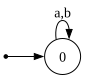

In [1]:
from automata_extensions.fa.dfa import ExtendedDFA

A1 = ExtendedDFA(
    states={"0"},
    input_symbols={"a", "b"},
    transitions={
        "0": {"a": "0", "b": "0"}
    },
    initial_state="0",
    final_states=set(),
)

A1.show_diagram()

In [2]:
print("Le langage est vide :", A1.is_empty())

Le langage est vide : True


## 2. Deuxième grammaire

Les règles de production sont :

$$
\begin{cases}
S \rightarrow AB \mid aA\\
A \rightarrow a\\
B \rightarrow b
\end{cases}
$$

On obtient deux dérivations possibles :

$$
S \Rightarrow AB \Rightarrow aB \Rightarrow ab
$$

$$
S \Rightarrow aA \Rightarrow aa
$$

Il n'existe aucune autre dérivation permettant de générer un mot.

### Conclusion

$$
\boxed{L(G_2)=\{aa,ab\}}
$$

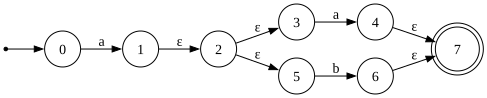

In [3]:
from automata_extensions.fa.nfa import ExtendedNFA

A2 = ExtendedNFA.from_regex(
    "a(a|b)",
    input_symbols={"a", "b"}
)

A2.show_diagram()

In [4]:
D2 = A2.determinize()

print(list(D2))

['aa', 'ab']


### Deuxième méthode : conversion directe de la grammaire

On peut également utiliser la méthode `from_grammar_string()` d'Automatix pour construire directement un automate à partir d'une grammaire régulière.

La grammaire initiale contient la règle $S \rightarrow AB$,
qui n'est pas une production régulière.

Cependant, puisque $A \rightarrow a$, on peut remplacer $AB$ par $aB$.

On obtient alors la grammaire régulière équivalente :

$$
\begin{cases}
S \rightarrow aB \mid aA\\
A \rightarrow a\\
B \rightarrow b
\end{cases}
$$

Cette grammaire génère le même langage :

$$
L(G_2)=\{aa,ab\}
$$

On utilise donc `from_grammar_string()` pour construire
l'AEFND équivalent, sans passer par une expression régulière.

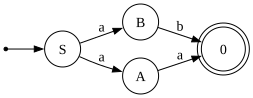

In [5]:
from automata_extensions.fa.nfa import ExtendedNFA

G2 = """
S -> aB | aA
A -> a
B -> b
"""

A2_grammar = ExtendedNFA.from_grammar_string(G2)

A2_grammar.show_diagram()

## 3. Troisième grammaire

Les règles de production sont :

$$
\begin{cases}
S \rightarrow AB \mid AA\\
A \rightarrow aB\\
B \rightarrow b
\end{cases}
$$

Le non-terminal $B$ génère $b$, tandis que $A$ génère $ab$.

On obtient deux dérivations possibles :

$$
S \Rightarrow AB \Rightarrow aBB
\Rightarrow abB \Rightarrow abb
$$

$$
S \Rightarrow AA \Rightarrow aBA
\Rightarrow abA \Rightarrow abaB \Rightarrow abab
$$

### Conclusion

$$
\boxed{L(G_3)=\{abb,abab\}}
$$

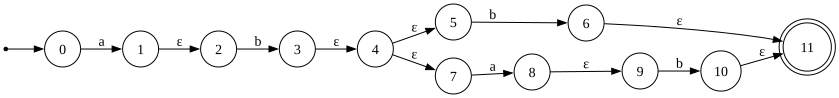

In [6]:
A3 = ExtendedNFA.from_regex(
    "ab(b|ab)",
    input_symbols={"a", "b"}
)

A3.show_diagram()

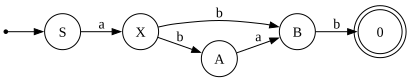

In [7]:
G3 = """
S -> aX
X -> bB | bA
A -> aB
B -> b
"""

A3_grammar = ExtendedNFA.from_grammar_string(G3)

A3_grammar.show_diagram()

## 4. Quatrième grammaire

Les règles de production sont :

$$
\begin{cases}
S \rightarrow AA \mid B\\
A \rightarrow aaA \mid aa\\
B \rightarrow bB \mid B
\end{cases}
$$

Le non-terminal $B$ ne peut jamais disparaître.
La branche $S \rightarrow B$ ne génère donc aucun mot.

Le non-terminal $A$ génère un nombre pair de $a$,
avec au minimum deux occurrences :

$$
L(A)=\{a^{2n}\mid n\geq 1\}
$$

Comme $S \rightarrow AA$, on concatène deux mots
générés par $A$.

### Conclusion

$$
\boxed{L(G_4)=\{a^{2n}\mid n\geq 2\}}
$$

Le langage contient les mots de longueur paire,
supérieure ou égale à 4, composés uniquement de $a$.

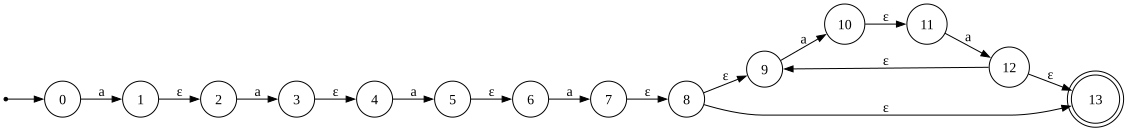

In [8]:
A4 = ExtendedNFA.from_regex(
    "aaaa(aa)*",
    input_symbols={"a", "b"}
)

A4.show_diagram()

### Deuxième méthode : conversion directe de la grammaire

On construit une grammaire régulière équivalente qui
génère quatre occurrences obligatoires de $a$, puis
un nombre quelconque de blocs $aa$.

$$
\begin{cases}
S \rightarrow aX\\
X \rightarrow aY\\
Y \rightarrow aZ\\
Z \rightarrow a \mid aT\\
T \rightarrow aZ
\end{cases}
$$

Les règles $Z \rightarrow aT$ et $T \rightarrow aZ$
permettent d'ajouter deux occurrences supplémentaires
de $a$ à chaque répétition.

On utilise `from_grammar_string()` pour construire
l'AEFND équivalent.

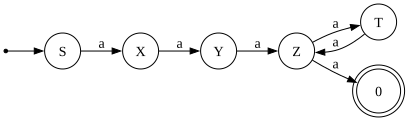

In [11]:
G4 = """
S -> aX
X -> aY
Y -> aZ
Z -> a | aT
T -> aZ
"""

A4_grammar = ExtendedNFA.from_grammar_string(G4)

A4_grammar = ExtendedNFA(
    states=A4_grammar.states,
    input_symbols={"a", "b"},
    transitions=A4_grammar.transitions,
    initial_state=A4_grammar.initial_state,
    final_states=A4_grammar.final_states,
)



A4_grammar.show_diagram()

In [12]:
D4_regex = A4.determinize()
D4_grammar = A4_grammar.determinize()

print(D4_regex.is_equivalent(D4_grammar))

True


## 5. Cinquième grammaire

Les règles de production sont :

$$
\begin{cases}
S \rightarrow AB \mid aAb\\
B \rightarrow bBa \mid \varepsilon\\
A \rightarrow \varepsilon
\end{cases}
$$

Le non-terminal $A$ génère uniquement le mot vide.

Le non-terminal $B$ génère les mots suivants :

$$
B \Rightarrow \varepsilon
$$

$$
B \Rightarrow bBa \Rightarrow ba
$$

$$
B \Rightarrow bBa \Rightarrow bbBaa
\Rightarrow bbaa
$$

Chaque répétition ajoute un $b$ à gauche et un $a$ à droite.

Ainsi :

$$
L(B)=\{b^na^n \mid n\geq 0\}
$$

Depuis $S$, on obtient deux possibilités :

- $S \Rightarrow AB \Rightarrow B$ ;
- $S \Rightarrow aAb \Rightarrow ab$.

### Conclusion

$$
\boxed{L(G_5)=\{b^na^n \mid n\geq 0\}\cup\{ab\}}
$$

Ce langage n'est pas régulier. Il ne peut donc pas être
reconnu par un automate à états finis.